In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
iso_data_dir = "../../../data/"
signal_type = "dynamic"  # dynamic or traditional
file_name = "012025_" + signal_type + ".csv"
file_path = iso_data_dir + file_name
date = "1/17/2025"

df = pd.read_csv(file_path)

print(df.head())

  Unnamed: 0  1/1/2025  1/2/2025  1/3/2025  1/4/2025  1/5/2025  1/6/2025  \
0    0:00:00 -0.999300  0.672976 -0.974665  0.038908 -0.059377 -0.028358   
1    0:00:02 -0.999241  0.652066 -0.965220  0.031900 -0.029303  0.036790   
2    0:00:04 -0.999973  0.635609 -0.947643  0.026199  0.001650  0.072859   
3    0:00:06 -0.999976  0.623370 -0.999633  0.013269  0.038735  0.148291   
4    0:00:08 -0.999980  0.613617 -0.999117 -0.003862  0.078129  0.222244   

   1/7/2025  1/8/2025  1/9/2025  ...  1/22/2025  1/23/2025  1/24/2025  \
0  0.649107 -0.609764  1.000063  ...   0.531411  -0.126601  -0.195508   
1  0.661217 -0.607512  0.999998  ...   0.502289  -0.137669  -0.192615   
2  0.665801 -0.598475  0.999995  ...   0.484451  -0.139485  -0.188004   
3  0.670476 -0.594001  0.999991  ...   0.441762  -0.158652  -0.179855   
4  0.672644 -0.588965  0.999988  ...   0.411880  -0.177566  -0.170049   

   1/25/2025  1/26/2025  1/27/2025  1/28/2025  1/29/2025  1/30/2025  1/31/2025  
0   0.123271  -0.767179

In [3]:
p_bar = 0 # MW
r = 1   # MW

ptarget = p_bar + df[date] * r

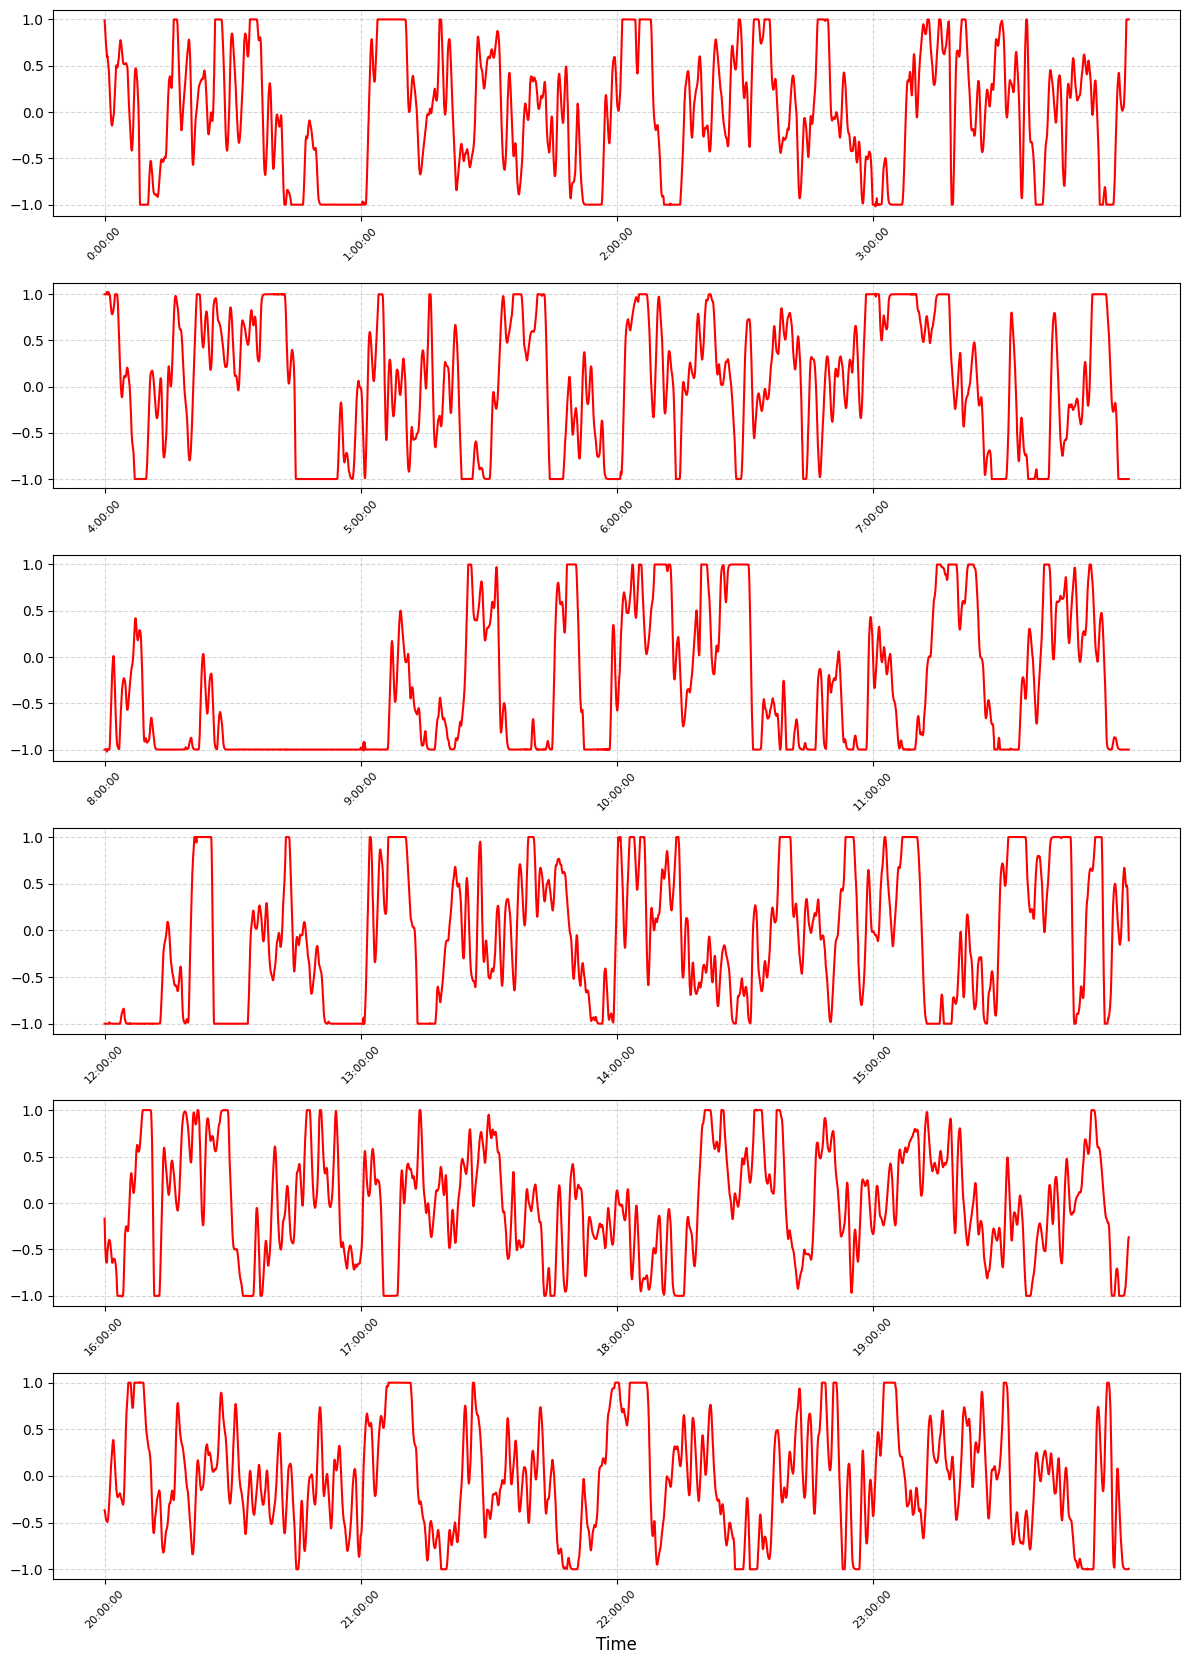

In [4]:
# Extract time labels (assuming the 0th column contains time)
time_labels = df.iloc[:, 0]  # Extract the 0th column for x-axis labels

# Ensure all time_labels are strings
time_labels = [str(label) for label in time_labels]

# Compute ptarget
ptarget = p_bar + df[date] * r

# Number of data points per hour
data_points_per_hour = 1800

# Number of data points per 4-hour interval
data_points_per_4_hours = data_points_per_hour * 4

# Create subplots
fig, axes = plt.subplots(6, 1, figsize=(12, 18))  # 6 rows, 1 column of subplots

# Create the 6 subplots for 4-hour intervals
for i in range(6):
    # Extract data for the current 4-hour interval
    start_idx = i * data_points_per_4_hours
    end_idx = start_idx + data_points_per_4_hours
    interval_time_labels = time_labels[start_idx:end_idx]
    interval_ptarget = ptarget[start_idx:end_idx]

    # Calculate ticks for each hour within the interval
    tick_positions = range(0, len(interval_time_labels), data_points_per_hour)
    tick_labels = [interval_time_labels[j] for j in tick_positions]

    # Plot data in the current subplot
    axes[i].plot(interval_time_labels, interval_ptarget, label=f'Interval {i + 1}', color='red', linestyle='-', markevery=data_points_per_hour)
    axes[i].set_xticks(tick_positions)  # Set x-axis ticks
    axes[i].set_xticklabels(tick_labels, rotation=45, fontsize=8)  # Set tick labels
    # axes[i].set_ylabel('P Target (MW)', fontsize=10)  # Label for y-axis
    axes[i].grid(visible=True, linestyle='--', alpha=0.5)  # Add grid
    # axes[i].legend(fontsize=10)  # Add legend

# Add a shared title and x-label
# fig.suptitle('P Target Over 24 Hours (Split into 4-Hour Intervals)', fontsize=14)
plt.xlabel('Time', fontsize=12)

# Optimize layout and display the plot
plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()


Mean ISO signal for 16:00–17:00: 0.043198


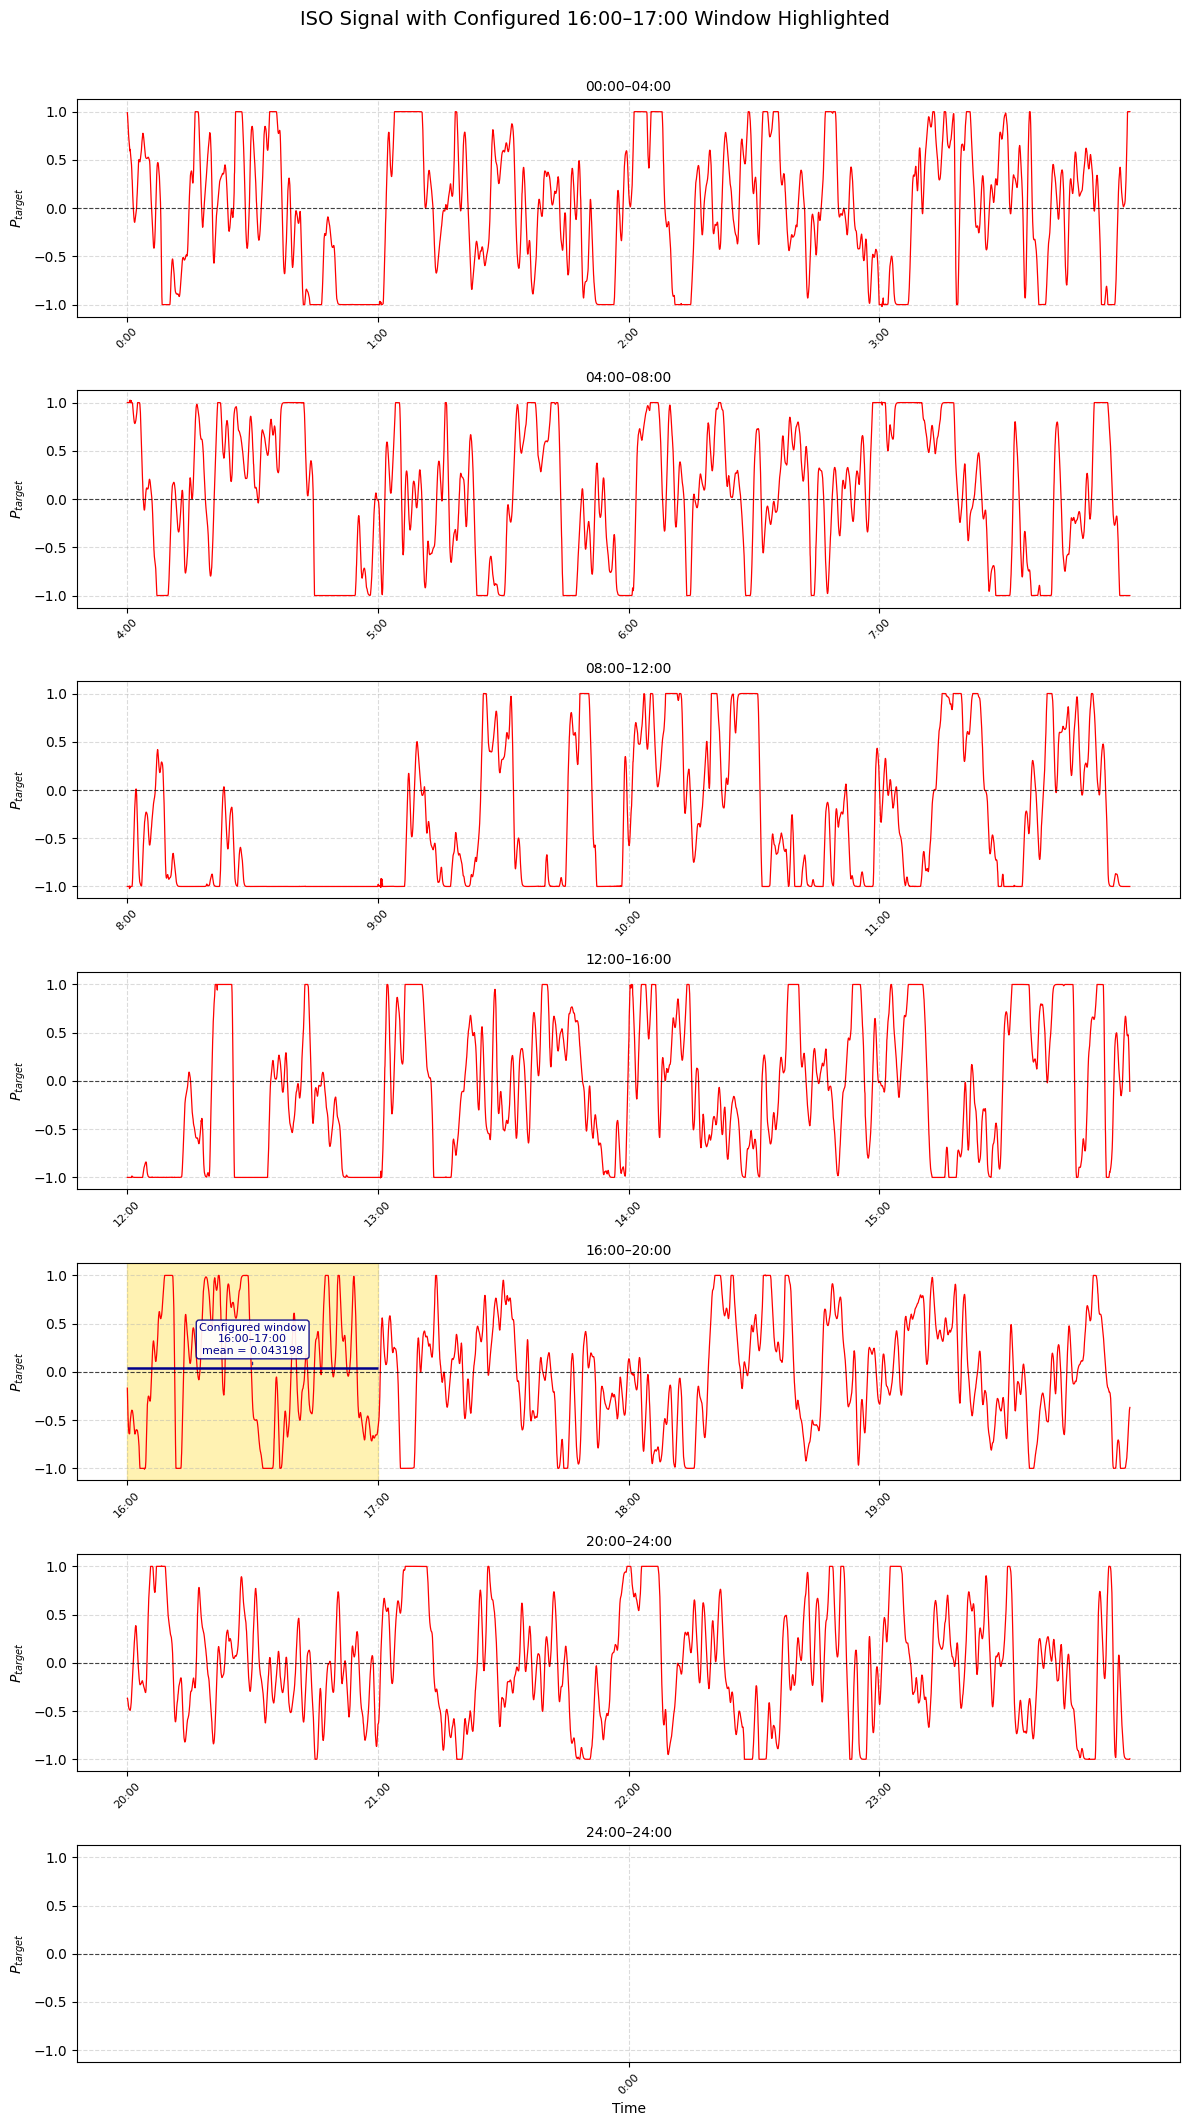

In [5]:
# ============================================================
# CHECK THE MEAN FOR THE CURRENT ISO CONFIGURATION
# Config:
#   normalize_iso_signal = True
#   randomize_iso_start = False
#   iso_signal_start_hour = 16
#
# This checks exactly the 16:00–17:00 ISO-signal window requested.
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data_points_per_hour = 1800  # 2-second ISO granularity
iso_signal_start_hour = 16
window_hours = 1             # "Just between 16-17"

# Recreate the exact signal used in this notebook.
time_labels = [str(label) for label in df.iloc[:, 0]]
ptarget = (p_bar + df[date] * r).reset_index(drop=True)

start_idx = iso_signal_start_hour * data_points_per_hour
end_idx = start_idx + window_hours * data_points_per_hour

if end_idx > len(ptarget):
    raise ValueError(
        f"Requested {iso_signal_start_hour:02d}:00–"
        f"{iso_signal_start_hour + window_hours:02d}:00, but the ISO "
        "signal does not contain that full interval."
    )

selected_signal = ptarget.iloc[start_idx:end_idx]
selected_mean = selected_signal.mean()

print(
    f"Mean ISO signal for {iso_signal_start_hour:02d}:00–"
    f"{iso_signal_start_hour + window_hours:02d}:00: "
    f"{selected_mean:.6f}"
)

# Same six 4-hour panels as Cell 4, with only 16:00–17:00 highlighted.
data_points_per_4_hours = 4 * data_points_per_hour
n_panels = int(np.ceil(len(ptarget) / data_points_per_4_hours))

fig, axes = plt.subplots(n_panels, 1, figsize=(12, 3 * n_panels), sharey=True)
if n_panels == 1:
    axes = [axes]

for panel_idx, ax in enumerate(axes):
    panel_start_idx = panel_idx * data_points_per_4_hours
    panel_end_idx = min(panel_start_idx + data_points_per_4_hours, len(ptarget))

    panel_signal = ptarget.iloc[panel_start_idx:panel_end_idx]
    panel_labels = time_labels[panel_start_idx:panel_end_idx]
    panel_x = np.arange(len(panel_signal))

    ax.plot(panel_x, panel_signal, color="red", linewidth=0.9)
    ax.axhline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.7)

    tick_positions = np.arange(0, len(panel_signal), data_points_per_hour)
    tick_labels = [
        ":".join(panel_labels[pos].split(":")[:2])
        for pos in tick_positions
    ]
    ax.set_xticks(tick_positions)
    ax.set_xticklabels(tick_labels, rotation=45, fontsize=8)
    ax.grid(visible=True, linestyle="--", alpha=0.45)

    # Highlight only the actual configured 16:00–17:00 signal window.
    overlap_start = max(start_idx, panel_start_idx)
    overlap_end = min(end_idx, panel_end_idx)

    if overlap_start < overlap_end:
        local_start = overlap_start - panel_start_idx
        local_end = overlap_end - panel_start_idx
        midpoint = (local_start + local_end) / 2

        ax.axvspan(local_start, local_end, color="gold", alpha=0.30)
        ax.hlines(
            y=selected_mean,
            xmin=local_start,
            xmax=local_end,
            color="darkblue",
            linewidth=1.8,
        )

        y_range = panel_signal.max() - panel_signal.min()
        y_offset = 0.06 * y_range if y_range else 0.01
        ax.annotate(
            f"Configured window\n16:00–17:00\nmean = {selected_mean:.6f}",
            xy=(midpoint, selected_mean),
            xytext=(midpoint, selected_mean + y_offset),
            ha="center",
            va="bottom",
            fontsize=8,
            color="darkblue",
            bbox=dict(
                boxstyle="round,pad=0.25",
                facecolor="white",
                edgecolor="darkblue",
                alpha=0.9,
            ),
            arrowprops=dict(arrowstyle="-", color="darkblue", linewidth=0.7),
        )

    panel_start_hour = panel_start_idx // data_points_per_hour
    panel_end_hour = min(panel_end_idx // data_points_per_hour, 24)
    ax.set_title(f"{panel_start_hour:02d}:00–{panel_end_hour:02d}:00", fontsize=10)
    ax.set_ylabel(r"$P_{target}$")

axes[-1].set_xlabel("Time")
fig.suptitle(
    "ISO Signal with Configured 16:00–17:00 Window Highlighted",
    fontsize=14,
    y=1.01,
)
plt.tight_layout()
plt.show()
